# Qualitative Comparative Analysis (fsQCA) — v3

Este notebook comienza **después de la calibración** realizada en `TESIS_preQCA_v3`.

**Entradas** (se leen directamente desde GitHub, carpeta `v2/data`):

- `qca_calibrada_tesis.csv`: la calibración principal, con una membresía por condición (generada como `qca_calibrada_tesis_v3.csv`);
- `barrido_calibraciones.csv`: las 68 membresías del barrido de umbrales (17 cruces por condición).

Cada caso representa un **gobierno regional en un año determinado (GORE–año)**. Analizaremos las condiciones `ALCANCE`, `COMPARTIDAS`, `CONCENTRACION` y `PERSISTENCIA`, y el resultado `INCO_ALTO`.

## ¿Qué haremos y para qué?

1. **Leer la base calibrada** para verificar los casos y las membresías que entran al análisis.
2. **Evaluar necesidad** para examinar si alguna condición, o su ausencia, es necesaria para `INCO_ALTO`.
3. **Construir la tabla de verdad** para organizar las combinaciones de condiciones y reconocer cuáles están representadas por los casos.
4. **Identificar configuraciones suficientes** para examinar qué combinaciones se asocian sistemáticamente con `INCO_ALTO`.
5. **Simplificar las configuraciones** mediante minimización lógica para obtener una expresión más parsimoniosa.
6. **Evaluar la solución** mediante consistencia, cobertura y PRI, y examinar también la solución asociada con `~INCO_ALTO`.
7. **Evaluar la sensibilidad** de los resultados a calibraciones alternativas del INCO.
8. **Barrer las combinaciones de umbrales**: repetir el fsQCA con miles de combinaciones de cruces de las cuatro condiciones para identificar en qué momento aparecen configuraciones suficientes.
9. **Construir un mapa de sensibilidad** para reconocer qué soluciones se repiten, en qué rango de umbrales y qué casos las sostienen.
10. **Examinar la ruta que más se repite** a medida que baja el cruce de `ALCANCE`.

Los pasos 1 a 7 replican `Tesis_QCA_v2` con la nueva calibración; los pasos 8 a 10 son nuevos. Los hallazgos estarán sujetos a los casos incluidos y a los umbrales de calibración utilizados.

Usaremos `setqca`, una implementación de fsQCA para Python.

In [1]:
!pip -q install setqca

"pip" no se reconoce como un comando interno o externo,
programa o archivo por lotes ejecutable.


## QCA-01: leer la base preparada

Cada fila representa un gobierno regional en un año determinado (GORE–año).

`ALCANCE`, `COMPARTIDAS`, `CONCENTRACION` y `PERSISTENCIA` son las membresías fuzzy de las condiciones, construidas en `TESIS_preQCA_v3` sobre las métricas normalizadas y con los cruces elegidos en preQCA-07: 0.25 para `ALCANCE`, 0.30 para `COMPARTIDAS`, 0.35 para `CONCENTRACION` y 0.50 para `PERSISTENCIA`. `INCO_ALTO` es la membresía del resultado, calibrada con los anclajes de cada año.

In [2]:
import pandas as pd
import numpy as np

# Archivos generados en TESIS_preQCA_v3, publicados en GitHub
linkQCA = "https://raw.githubusercontent.com/romloayza/networks_x_qca_tesis/refs/heads/main/v2/data/qca_calibrada_tesis.csv"
linkBarrido = "https://raw.githubusercontent.com/romloayza/networks_x_qca_tesis/refs/heads/main/v2/data/barrido_calibraciones.csv"

qca = pd.read_csv(linkQCA)
barrido = pd.read_csv(linkBarrido)

CONDICIONES = ["ALCANCE", "COMPARTIDAS", "CONCENTRACION", "PERSISTENCIA"]

print("Casos:", len(qca))
qca.head()

Casos: 69


,caso,AÑO,ALCANCE,COMPARTIDAS,CONCENTRACION,PERSISTENCIA,INCO_ALTO,INCO_ALTO_ORIGINAL,INCO_ALTO_FIJO
0,AMAZONAS_2021,2021,0.240756,0.084432,0.007117,0.331578,0.050000,0.936681,0.377410
1,AMAZONAS_2022,2022,0.136505,0.015039,0.999755,0.105869,0.047907,0.926370,0.304821
2,AMAZONAS_2024,2024,0.526079,0.062638,0.002697,0.209768,0.001520,0.463261,0.002059
3,ANCASH_2021,2021,0.996575,0.016233,0.001424,0.345852,0.950000,0.996754,0.996185
4,ANCASH_2022,2022,1.000000,0.024672,0.001076,0.142207,0.990124,0.993441,0.984506


## QCA-02: buscar condiciones necesarias

Una condición necesaria responde a la pregunta:

> Cuando encontramos un GORE–año con pertenencia a `INCO_ALTO`, ¿encontramos también pertenencia a la condición?

Usaremos `necessity_analysis()` para evaluar `ALCANCE`, `COMPARTIDAS`, `CONCENTRACION` y `PERSISTENCIA`, así como sus ausencias, respecto de `INCO_ALTO`.

Tomamos una consistencia de 0.90 como referencia para identificar una relación de necesidad fuerte. También examinaremos la cobertura y la relevancia de la necesidad (RoN), que permite advertir cuándo una condición está presente en casi todos los casos y su necesidad resulta trivial.

In [3]:
from setqca import necessity_analysis

necesidad = necessity_analysis(
    qca,
    outcome="INCO_ALTO",
    conditions=CONDICIONES,
    consistency_threshold=0.90
)

necesidad.to_frame()[
    ["condition", "consistency", "coverage", "RoN", "necessary"]
].round(3)

,condition,consistency,coverage,RoN,necessary
0,~COMPARTIDAS,0.822,0.503,0.394,False
1,~CONCENTRACION,0.810,0.466,0.313,False
2,~PERSISTENCIA,0.799,0.487,0.384,False
3,~ALCANCE,0.770,0.472,0.382,False
4,ALCANCE,0.356,0.671,0.903,False
5,PERSISTENCIA,0.331,0.631,0.895,False
6,COMPARTIDAS,0.316,0.598,0.885,False
7,CONCENTRACION,0.280,0.660,0.924,False


### ¿Cómo leer el resultado?

Ninguna condición, ni su ausencia, alcanza el umbral de consistencia de 0.90. Las mayores consistencias corresponden a las ausencias: `~COMPARTIDAS` (0.822), `~CONCENTRACION` (0.810), `~PERSISTENCIA` (0.799) y `~ALCANCE` (0.770).

Además, la relevancia de esas ausencias es baja (RoN entre 0.31 y 0.39): con los cruces de la calibración principal, la mayoría de los GORE–año queda fuera de cada condición, también los de menor INCO, por lo que estar fuera de una condición no distingue a los GORE–año con `INCO_ALTO`.

Por tanto, **ninguna condición individual ni su ausencia puede considerarse necesaria para `INCO_ALTO`**. A continuación examinaremos si sus **combinaciones** constituyen configuraciones suficientes.

## QCA-03: observar combinaciones

Con cuatro condiciones existen `2⁴ = 16` configuraciones lógicamente posibles de `ALCANCE`, `COMPARTIDAS`, `CONCENTRACION` y `PERSISTENCIA`.

`build_truth_table()` organiza esas configuraciones. Los casos GORE–año se ubican en una fila según estén más dentro —membresía superior a 0.5— o más fuera —membresía inferior a 0.5— de cada conjunto. Los casos con membresía exactamente igual a 0.5 se excluyen provisionalmente, pues se encuentran en el punto de máxima ambigüedad.

La consistencia de cada fila respecto de `INCO_ALTO` se calcula utilizando las membresías fuzzy originales.

In [4]:
from setqca import build_truth_table

casos_cruce = qca.loc[
    (qca[CONDICIONES + ["INCO_ALTO"]] == 0.5).any(axis=1)
]
print("Casos con membresía igual a 0.5:", casos_cruce["caso"].tolist())

qca_tabla = qca.loc[
    ~qca["caso"].isin(casos_cruce["caso"])
].copy()

print("Casos en la tabla de verdad:", len(qca_tabla),
      "| dentro de INCO_ALTO (> 0.5):", int((qca_tabla["INCO_ALTO"] > 0.5).sum()))

tabla = build_truth_table(
    qca_tabla,
    outcome="INCO_ALTO",
    conditions=CONDICIONES,
    inclusion_cutoff=0.80,
    pri_cutoff=0.50,
    frequency_cutoff=1,
    case_id="caso"
)

tabla_df = tabla.to_frame()

tabla_df[CONDICIONES + ["n", "consistency", "PRI", "OUT", "cases"]].round(3)

Casos con membresía igual a 0.5: ['AYACUCHO_2021', 'HUANCAVELICA_2022', 'LORETO_2021', 'TUMBES_2024', 'UCAYALI_2024']
Casos en la tabla de verdad: 64 | dentro de INCO_ALTO (> 0.5): 28


,ALCANCE,COMPARTIDAS,CONCENTRACION,PERSISTENCIA,n,consistency,PRI,OUT,cases
0,0,0,0,0,22,0.492,0.312,0,"AMAZONAS_2021, AREQUIPA_2022, CAJAMARCA_2024, ..."
1,0,0,0,1,7,0.492,0.222,0,"CAJAMARCA_2021, CAJAMARCA_2022, HUANCAVELICA_2..."
2,0,0,1,0,9,0.589,0.435,0,"AMAZONAS_2022, APURIMAC_2022, AREQUIPA_2021, C..."
3,0,0,1,1,1,0.815,0.599,1,TUMBES_2022
4,0,1,0,0,8,0.587,0.377,0,"ANCASH_2024, AYACUCHO_2022, CUSCO_2024, LAMBAY..."
5,0,1,0,1,1,0.545,0.093,0,AYACUCHO_2024
6,0,1,1,0,1,0.873,0.759,1,JUNIN_2022
7,0,1,1,1,1,0.679,0.164,0,APURIMAC_2021
8,1,0,0,0,11,0.695,0.507,0,"AMAZONAS_2024, ANCASH_2021, ANCASH_2022, AREQU..."
9,1,0,0,1,2,0.812,0.695,1,"LORETO_2022, LORETO_2024"


### ¿Cómo leer el resultado?

Cinco casos tienen una membresía igual a 0.5 en alguna condición o en el resultado y quedan fuera de la tabla: Ayacucho 2021, Huancavelica 2022, Loreto 2021, Tumbes 2024 y Ucayali 2024. La tabla trabaja con 64 GORE–año, de los cuales 28 están más dentro que fuera de `INCO_ALTO`.

De las 16 configuraciones posibles, 11 tienen casos observados y 5 carecen de ellos (`OUT = R`, remanentes lógicos). Los casos se concentran en pocas filas: la configuración `0 0 0 0`, sin pertenencia a ninguna condición, reúne a 22 GORE–año, y la configuración `1 0 0 0` a 11.

## QCA-04: identificar configuraciones suficientes

Ahora preguntamos:

> Cuando un GORE–año presenta una configuración de condiciones, ¿presenta también pertenencia a `INCO_ALTO` de manera sistemática?

`OUT = 1` identifica las configuraciones que cumplen los criterios establecidos: consistencia mínima de 0.80, PRI mínimo de 0.50 y frecuencia mínima de un caso. Son los mismos criterios de `Tesis_QCA_v2`.

In [5]:
columnas = CONDICIONES + ["n", "consistency", "PRI", "OUT", "cases"]

suficientes = tabla_df[
    tabla_df["OUT"].astype(str) == "1"
][columnas]

suficientes.round(3)

,ALCANCE,COMPARTIDAS,CONCENTRACION,PERSISTENCIA,n,consistency,PRI,OUT,cases
3,0,0,1,1,1,0.815,0.599,1,TUMBES_2022
6,0,1,1,0,1,0.873,0.759,1,JUNIN_2022
9,1,0,0,1,2,0.812,0.695,1,"LORETO_2022, LORETO_2024"


### ¿Qué observamos?

A diferencia de `Tesis_QCA_v2`, ahora **tres configuraciones cumplen el criterio de suficiencia**:

| Configuración | Casos | Consistencia | Lectura |
|---|---:|---:|---|
| `0 0 1 1` | 1 | 0.815 | sin alto alcance, sin contratistas compartidos, con concentración y persistencia |
| `0 1 1 0` | 1 | 0.873 | sin alto alcance, con contratistas compartidos y concentración, sin persistencia |
| `1 0 0 1` | 2 | 0.812 | alto alcance, sin contratistas compartidos ni concentración, con persistencia |

Sin embargo, las tres filas están representadas por **uno o dos casos**. Una configuración suficiente sostenida por un solo GORE–año describe a ese gobierno regional, pero no constituye un patrón entre gobiernos regionales. Retomaremos este punto en el barrido (QCA-08), exigiendo una frecuencia mínima mayor.

## QCA-05: simplificar las configuraciones

Utilizamos `FSQCA` para minimizar las configuraciones suficientes asociadas con `INCO_ALTO` y obtener una expresión lógica más parsimoniosa. Aplicaremos los mismos criterios de QCA-03: consistencia mínima de 0.80, frecuencia mínima de 1 y PRI mínimo de 0.50.

Revisaremos dos soluciones:

- la **conservadora**, que solo utiliza las configuraciones observadas;
- la **parsimoniosa**, que además utiliza los remanentes lógicos (configuraciones sin casos) cuando simplifican la expresión.

In [6]:
from setqca import FSQCA

modelo_qca = FSQCA(
    consistency=0.80,
    pri=0.50,
    frequency=1
)

resultado_qca = modelo_qca.fit(
    qca_tabla,
    outcome="INCO_ALTO",
    conditions=CONDICIONES,
    case_id="caso"
)

resumen_qca = pd.concat([
    resultado_qca.summary_frame("conservative").assign(familia="conservadora"),
    resultado_qca.summary_frame("parsimonious").assign(familia="parsimoniosa")
])

with pd.option_context("display.max_colwidth", None):
    display(resumen_qca[["familia", "solution", "consistency", "coverage", "PRI"]].round(3))

,familia,solution,consistency,coverage,PRI
0,conservadora,~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + ~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA + ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA,0.842,0.269,0.741
0,parsimoniosa,ALCANCE*PERSISTENCIA + ~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + COMPARTIDAS*CONCENTRACION*~PERSISTENCIA,0.843,0.269,0.742


### ¿Cómo leer el resultado?

La **solución conservadora** reúne las tres configuraciones suficientes sin simplificarlas, porque no comparten condiciones que puedan eliminarse:

`~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + ~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA + ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA`

En esta expresión, `*` significa combinación de condiciones —Y—, `+` representa rutas alternativas —O— y `~` indica la negación de un conjunto.

La **solución parsimoniosa** (`ALCANCE*PERSISTENCIA + ~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + COMPARTIDAS*CONCENTRACION*~PERSISTENCIA`) es más breve porque asume que algunas configuraciones sin casos también producirían el resultado. Esa suposición no se apoya en casos observados, por lo que la interpretaremos con cautela.

## QCA-06: evaluar la solución

La **consistencia** indica en qué medida la membresía en la solución es un subconjunto de la membresía en `INCO_ALTO`. La **cobertura** indica cuánto de la membresía en `INCO_ALTO` queda cubierto por la solución; no representa varianza explicada. El **PRI** permite evaluar la ambigüedad de la relación de suficiencia: valores elevados indican que la relación corresponde al resultado y no simultáneamente a su ausencia.

Calcularemos estos parámetros para cada ruta de la solución conservadora, junto con su **cobertura única** (la parte del resultado que solo esa ruta cubre) y sus **casos típicos** (GORE–año que pertenecen a la ruta y al resultado).

In [7]:
from setqca import sufficiency_diagnostics

def parametros_rutas(datos, resultado, solucion):
    rutas = solucion.split(" + ")
    diagnostico = sufficiency_diagnostics(datos, outcome=resultado, terms=rutas, case_id="caso")
    return pd.DataFrame([{
        "ruta": t.expression,
        "consistencia": round(t.fit.consistency, 3),
        "cobertura": round(t.fit.coverage, 3),
        "cobertura única": round(t.unique_coverage, 3),
        "PRI": round(t.fit.pri, 3),
        "casos típicos": ", ".join(t.typical),
    } for t in diagnostico.terms])

solucion_conservadora = resultado_qca.summary_frame("conservative").iloc[0]["solution"]

with pd.option_context("display.max_colwidth", None):
    display(parametros_rutas(qca_tabla, "INCO_ALTO", solucion_conservadora))

,ruta,consistencia,cobertura,cobertura única,PRI,casos típicos
0,~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA,0.815,0.049,0.025,0.599,TUMBES_2022
1,~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA,0.873,0.113,0.097,0.759,JUNIN_2022
2,ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA,0.812,0.144,0.123,0.695,"LORETO_2022, LORETO_2024"


### ¿Cómo leer el resultado?

La solución conjunta tiene una consistencia de 0.842, una cobertura de 0.269 y un PRI de 0.741: cumple los criterios de suficiencia, pero cubre algo más de una cuarta parte de la membresía en `INCO_ALTO`.

| Ruta | Casos típicos | Interpretación |
|---|---|---|
| `~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA` | Tumbes 2022 | Pocas empresas, exclusivas del GORE, con el monto concentrado y que ya habían contratado antes con él. |
| `~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA` | Junín 2022 | Pocas empresas, que también contratan con otros GORE, con el monto concentrado y sin vínculos previos. |
| `ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA` | Loreto 2022 y 2024 | Muchas empresas, exclusivas del GORE, con el monto disperso y con vínculos previos. |

Cada ruta descansa en uno o dos GORE–año y su cobertura no supera 0.15. Las rutas además se contradicen entre sí: unas exigen `CONCENTRACION` y otras su ausencia; unas `PERSISTENCIA` y otras su ausencia. Por ello, esta solución **describe casos particulares más que un patrón general** y debe leerse junto con el barrido de QCA-08.

Como las relaciones de conjuntos son asimétricas, examinamos también la solución para la ausencia del resultado, `~INCO_ALTO`.

In [8]:
qca_neg = qca_tabla.copy()
qca_neg["NO_INCO_ALTO"] = 1 - qca_neg["INCO_ALTO"]

resultado_neg = FSQCA(consistency=0.80, pri=0.50, frequency=1).fit(
    qca_neg,
    outcome="NO_INCO_ALTO",
    conditions=CONDICIONES,
    case_id="caso"
)

resumen_neg = resultado_neg.summary_frame("conservative")

with pd.option_context("display.max_colwidth", None):
    display(resumen_neg[["solution", "consistency", "coverage", "PRI"]].round(3))
    display(parametros_rutas(qca_neg, "NO_INCO_ALTO", resumen_neg.iloc[0]["solution"]))

,solution,consistency,coverage,PRI
0,~ALCANCE*COMPARTIDAS*~CONCENTRACION*PERSISTENCIA + ALCANCE*COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA,0.857,0.146,0.701


,ruta,consistencia,cobertura,cobertura única,PRI,casos típicos
0,~ALCANCE*COMPARTIDAS*~CONCENTRACION*PERSISTENCIA,0.954,0.076,0.037,0.907,AYACUCHO_2024
1,ALCANCE*COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA,0.831,0.109,0.070,0.582,HUANUCO_2024


### ¿Cómo leer el resultado?

Para `~INCO_ALTO` la solución conservadora tiene dos rutas, `~ALCANCE*COMPARTIDAS*~CONCENTRACION*PERSISTENCIA` (Ayacucho 2024) y `ALCANCE*COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA` (Huánuco 2024), con una consistencia conjunta de 0.857 y una cobertura de 0.146.

Ambas comparten `COMPARTIDAS*~CONCENTRACION`: contratistas que también trabajan con otros gobiernos regionales y un monto poco concentrado. Es la misma combinación que `Tesis_QCA_v2` identificó como indicio en su análisis de sensibilidad. Como cada ruta descansa en un solo caso, también debe leerse como un indicio.

## QCA-07: evaluar la sensibilidad a la calibración del INCO

Compararemos la calibración del INCO por año con la calibración inicial (30, 50 y 70, `INCO_ALTO_ORIGINAL`) y con anclajes fijos para todos los años (60, 70 y 80, `INCO_ALTO_FIJO`), manteniendo las condiciones de la calibración principal y los criterios de QCA-04.

In [9]:
def resolver(datos, resultado, condiciones=CONDICIONES, consistencia=0.80, frecuencia=1):
    try:
        r = FSQCA(consistency=consistencia, pri=0.50, frequency=frecuencia).fit(
            datos, outcome=resultado, conditions=condiciones, case_id="caso"
        )
        salida = {}
        for familia in ["conservative", "parsimonious"]:
            s = r.summary_frame(familia).iloc[0]
            salida[familia] = f'{s["solution"]}  (cons={s["consistency"]:.3f}, cob={s["coverage"]:.3f}, PRI={s["PRI"]:.3f})'
        return salida
    except ValueError:
        return {"conservative": "sin configuraciones suficientes", "parsimonious": "—"}

filas = []
for version in ["INCO_ALTO", "INCO_ALTO_FIJO", "INCO_ALTO_ORIGINAL"]:
    solucion = resolver(qca_tabla, version)
    dentro = qca_tabla[version] > 0.5
    filas.append({
        "calibración del INCO": version,
        "casos dentro (>0.5)": int(dentro.sum()),
        "2021 / 2022 / 2024": " / ".join(str(int((dentro & (qca_tabla["AÑO"] == a)).sum())) for a in [2021, 2022, 2024]),
        "solución conservadora": solucion["conservative"],
        "solución parsimoniosa": solucion["parsimonious"],
    })

with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(filas))

,calibración del INCO,casos dentro (>0.5),2021 / 2022 / 2024,solución conservadora,solución parsimoniosa
0,INCO_ALTO,28,11 / 8 / 9,"~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + ~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA + ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA (cons=0.842, cob=0.269, PRI=0.741)","ALCANCE*PERSISTENCIA + ~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + COMPARTIDAS*CONCENTRACION*~PERSISTENCIA (cons=0.843, cob=0.269, PRI=0.742)"
1,INCO_ALTO_FIJO,31,17 / 12 / 2,"~ALCANCE*~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + ~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA (cons=0.860, cob=0.126, PRI=0.775)","~COMPARTIDAS*CONCENTRACION*PERSISTENCIA + COMPARTIDAS*CONCENTRACION*~PERSISTENCIA (cons=0.860, cob=0.127, PRI=0.776)"
2,INCO_ALTO_ORIGINAL,61,21 / 22 / 18,"~ALCANCE + ~COMPARTIDAS*~CONCENTRACION + ~CONCENTRACION*~PERSISTENCIA (cons=0.923, cob=0.980, PRI=0.914)","1 (cons=0.900, cob=1.000, PRI=0.889)"


### ¿Cómo leer el resultado?

Con la calibración inicial (30, 50 y 70) casi todos los casos pertenecen a `INCO_ALTO` y la solución parsimoniosa es `1`: el resultado aparecería con cualquier combinación de condiciones, por lo que esa calibración no permite distinguir entre configuraciones.

Con anclajes fijos (60, 70 y 80) se mantienen dos de las tres rutas de la solución principal, las que combinan `~ALCANCE` con `CONCENTRACION`. Sin embargo, los casos con INCO alto se concentran en 2021 y 2022, por lo que esa calibración refleja en buena medida la diferencia entre años.

La calibración por año sigue siendo la referencia del análisis.

## QCA-08: barrer las combinaciones de umbrales

Hasta aquí hemos analizado **una sola calibración**. Pero, como vimos en `TESIS_preQCA_v3`, la relación de cada condición con `INCO_ALTO` cambia según el cruce elegido. La pregunta ahora es:

> ¿En qué combinaciones de umbrales aparecen configuraciones suficientes para `INCO_ALTO`, y cuáles se repiten?

Para responderla repetiremos el fsQCA con muchas combinaciones de cruces, utilizando las membresías ya calculadas en `barrido_calibraciones.csv`:

- para cada condición tomaremos los cruces de **0.90 a 0.10 en pasos de 0.10** (9 valores);
- combinaremos los cruces de las cuatro condiciones: 9 × 9 × 9 × 9 = **6 561 combinaciones**;
- en cada combinación excluiremos los casos con membresía igual a 0.5 y ejecutaremos `FSQCA` con consistencia mínima de 0.80 y PRI mínimo de 0.50, como en QCA-04.

### ¿Por qué variar la frecuencia mínima?

En QCA-04 vimos que una configuración puede resultar suficiente con un solo caso. Con miles de combinaciones, es esperable que en muchas de ellas algún GORE–año aislado forme una fila consistente. Para distinguir esas soluciones de patrones más amplios repetiremos el barrido con **frecuencia mínima de 1, 2 y 3 casos por fila**.

Además, para cada solución registraremos cuántos casos **la sostienen**: GORE–año que pertenecen más dentro que fuera a la solución y al resultado (`casos_consistentes`).

La ejecución puede tardar unos minutos.

In [10]:
import itertools
import time
from setqca import evaluate_expression

CRUCES_BARRIDO = [0.90, 0.80, 0.70, 0.60, 0.50, 0.40, 0.30, 0.20, 0.10]
FRECUENCIAS = [1, 2, 3]

def correr_combinacion(cruces, frecuencia):
    datos = pd.DataFrame({"caso": barrido["caso"], "AÑO": barrido["AÑO"], "INCO_ALTO": barrido["INCO_ALTO"]})
    for conjunto, cruce in zip(CONDICIONES, cruces):
        datos[conjunto] = barrido[f"{conjunto}_c{cruce:.2f}"]
    datos = datos[~np.isclose(datos[CONDICIONES + ["INCO_ALTO"]], 0.5).any(axis=1)].reset_index(drop=True)

    fila = {**dict(zip(CONDICIONES, cruces)), "frecuencia": frecuencia, "casos": len(datos)}
    try:
        r = FSQCA(consistency=0.80, pri=0.50, frequency=frecuencia).fit(
            datos, outcome="INCO_ALTO", conditions=CONDICIONES, case_id="caso"
        )
    except ValueError:
        return {**fila, "solucion": None}

    s = r.summary_frame("conservative").iloc[0]
    membresia = evaluate_expression(s["solution"], datos[CONDICIONES])
    sostienen = (membresia > 0.5) & (datos["INCO_ALTO"] > 0.5)
    return {
        **fila,
        "solucion": s["solution"],
        "consistencia": s["consistency"],
        "cobertura": s["coverage"],
        "PRI": s["PRI"],
        "casos_en_solucion": int((membresia > 0.5).sum()),
        "casos_consistentes": int(sostienen.sum()),
        "lista_casos": ", ".join(datos.loc[sostienen, "caso"])
    }

inicio = time.time()
resultados = []
for frecuencia in FRECUENCIAS:
    for cruces in itertools.product(CRUCES_BARRIDO, repeat=len(CONDICIONES)):
        resultados.append(correr_combinacion(cruces, frecuencia))
    print(f"Frecuencia mínima {frecuencia}: listo ({time.time() - inicio:.0f} s)")

barrido_qca = pd.DataFrame(resultados)
barrido_qca["hay_solucion"] = barrido_qca["solucion"].notna()

print("Corridas:", len(barrido_qca))

Frecuencia mínima 1: listo (20 s)


Frecuencia mínima 2: listo (39 s)


Frecuencia mínima 3: listo (53 s)
Corridas: 19683


## QCA-09: construir el mapa de sensibilidad

Resumiremos el barrido en tres pasos:

1. ¿En qué proporción de las combinaciones aparece una solución y cuántos casos la sostienen?
2. ¿Cómo cambia esa proporción a medida que baja el cruce de cada condición?
3. ¿Qué rutas y qué casos se repiten?

In [11]:
resumen_barrido = barrido_qca.groupby("frecuencia").agg(
    combinaciones=("hay_solucion", "size"),
    con_solucion=("hay_solucion", "mean"),
    con_solucion_y_3_casos=("casos_consistentes", lambda s: (s >= 3).mean()),
    mediana_casos_consistentes=("casos_consistentes", "median"),
)

resumen_barrido["con_solucion"] = (100 * resumen_barrido["con_solucion"]).round(1).astype(str) + " %"
resumen_barrido["con_solucion_y_3_casos"] = (100 * resumen_barrido["con_solucion_y_3_casos"]).round(1).astype(str) + " %"

resumen_barrido

,combinaciones,con_solucion,con_solucion_y_3_casos,mediana_casos_consistentes
frecuencia,,,,
1,6561,81.1 %,29.9 %,2.0
2,6561,51.6 %,20.3 %,2.0
3,6561,17.9 %,17.7 %,4.0


### ¿Cómo leer el resultado?

Con frecuencia mínima de 1 caso, el 81 % de las combinaciones produce una solución para `INCO_ALTO`, pero la mediana de casos que la sostienen es **2**: la mayoría de esas soluciones descansa en uno o dos GORE–año. Solo el 30 % de las combinaciones tiene una solución sostenida por al menos 3 casos.

Al exigir al menos 3 casos por fila, la proporción de combinaciones con solución baja al 18 %, y casi todas ellas están sostenidas por 3 o más casos. **Estas son las soluciones que merecen atención**: aparecen con una frecuencia mínima más exigente y no dependen de un GORE–año aislado.

In [12]:
por_cruce = pd.concat({
    conjunto: barrido_qca.groupby(["frecuencia", conjunto])["hay_solucion"].mean().unstack(conjunto)
    for conjunto in CONDICIONES
}, axis=1)

(100 * por_cruce).round(0)

ALCANCE                                                       \
ALCANCE        0.1   0.2   0.3   0.4    0.5    0.6    0.7    0.8    0.9   
frecuencia                                                                
1             39.0  61.0  59.0  71.0  100.0  100.0  100.0  100.0  100.0   
2              6.0  29.0  12.0  42.0  100.0   89.0   89.0   89.0    7.0   
3              2.0  11.0   9.0  40.0   88.0    3.0    3.0    3.0    3.0   

           COMPARTIDAS  ... CONCENTRACION PERSISTENCIA                    \
ALCANCE            0.1  ...           0.9          0.1   0.2   0.3   0.4   
frecuencia              ...                                                
1                 94.0  ...          75.0         84.0  87.0  89.0  75.0   
2                 58.0  ...          50.0         57.0  67.0  60.0  27.0   
3                 15.0  ...          17.0         24.0  25.0  23.0  13.0   

                                           
ALCANCE      0.5    0.6   0.7   0.8   0.9  
frecuencia                                 
1           85.0  100.0  68.0  71.0  71.0  
2           51.0   52.0  50.0  50.0  50.0  
3           14.0   15.0  16.0  16.0  16.0  

[3 rows x 36 columns]

### ¿Cómo leer el resultado?

Cada celda indica el porcentaje de combinaciones con solución cuando la condición de la columna tiene ese cruce, cualquiera sea el cruce de las demás.

La condición que más ordena los resultados es **`ALCANCE`**. Con frecuencia mínima de 3 casos, cuando el cruce de `ALCANCE` es 0.50 aparece una solución en el 88 % de las combinaciones de las demás condiciones; con 0.40, en el 40 %; con los demás cruces, en el 11 % o menos. Las otras tres condiciones no muestran un patrón tan marcado: con frecuencia mínima de 3, la proporción de combinaciones con solución se mantiene entre el 13 % y el 35 % cualquiera sea su cruce.

El gráfico muestra este resultado para las tres frecuencias mínimas.

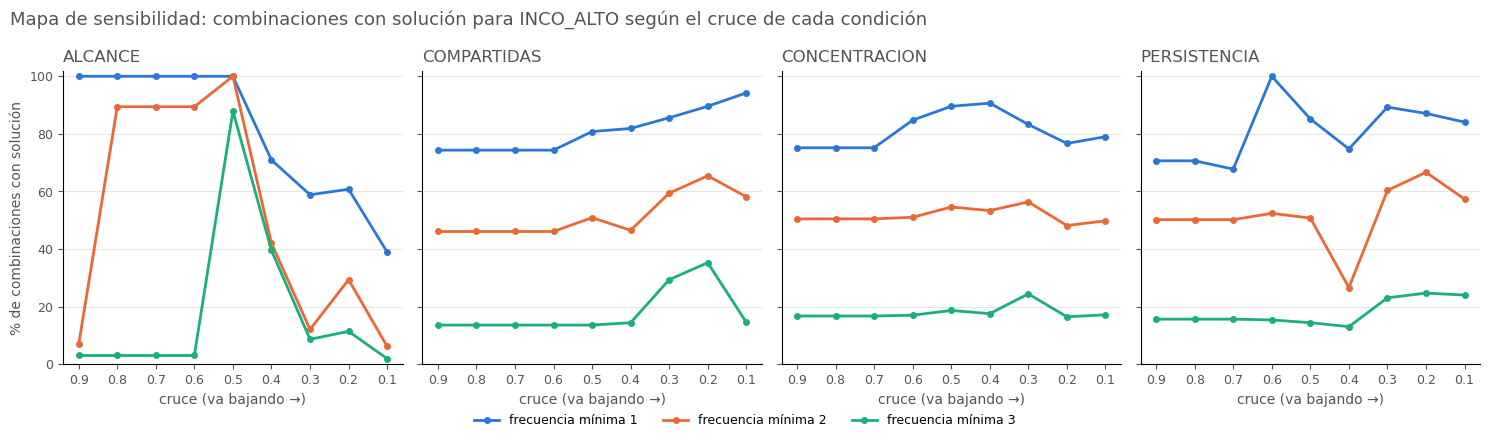

In [13]:
import matplotlib.pyplot as plt

AZUL, NARANJA, AGUA, GRIS, TEXTO = "#2a78d6", "#eb6834", "#1baf7a", "#b8b8b0", "#55554f"
COLORES = {1: AZUL, 2: NARANJA, 3: AGUA}

fig, ejes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)

for eje, conjunto in zip(ejes, CONDICIONES):
    for frecuencia in FRECUENCIAS:
        serie = 100 * por_cruce.loc[frecuencia, conjunto]
        eje.plot(serie.index, serie.values, color=COLORES[frecuencia], linewidth=2, marker="o", markersize=4,
                 label=f"frecuencia mínima {frecuencia}")
    eje.set_title(conjunto, color=TEXTO, fontsize=12, loc="left")
    eje.set_xlabel("cruce (va bajando →)", color=TEXTO)
    eje.set_ylim(0, 102)
    eje.spines[["top", "right"]].set_visible(False)
    eje.tick_params(colors=TEXTO, labelsize=9)
    eje.grid(axis="y", color="#e6e6e1", linewidth=0.8)
    eje.set_axisbelow(True)

for eje in ejes:  # el eje x no es compartido: invertir cada panel
    eje.invert_xaxis()
ejes[0].set_ylabel("% de combinaciones con solución", color=TEXTO)
handles, labels = ejes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, fontsize=9, loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))

fig.suptitle("Mapa de sensibilidad: combinaciones con solución para INCO_ALTO según el cruce de cada condición",
             color=TEXTO, x=0.01, ha="left", fontsize=13)
fig.tight_layout()
plt.show()

### ¿Cómo leer el gráfico?

Cada panel corresponde a una condición; el eje horizontal muestra su cruce, que **baja de izquierda a derecha**, y cada línea corresponde a una frecuencia mínima.

En el panel de `ALCANCE` se observa un pico en el cruce de 0.50 que se mantiene aunque se exija una frecuencia mínima de 3 casos. En los demás paneles, las líneas son más planas: la aparición de soluciones depende sobre todo del umbral de `ALCANCE`.

Con los cruces altos de `ALCANCE` (0.60 a 0.80) también aparecen soluciones en casi todas las combinaciones con frecuencia mínima de 1 o 2, pero desaparecen al exigir 3 casos: descansan en Áncash 2022 y Junín 2024, los dos GORE–año con más contratistas.

Ahora identificaremos qué rutas componen las soluciones del barrido y qué casos las sostienen. Utilizaremos las corridas con **frecuencia mínima de 3 casos**, que son las más exigentes.

Una solución puede tener varias rutas unidas por `+`; contaremos cuántas veces aparece cada ruta en el total de combinaciones.

In [14]:
exigente = barrido_qca[(barrido_qca["frecuencia"] == 3) & barrido_qca["hay_solucion"]]

rutas_frecuentes = (
    exigente["solucion"].str.split(" + ", regex=False).explode()
    .value_counts().rename("combinaciones").to_frame()
)
rutas_frecuentes["% del barrido"] = (100 * rutas_frecuentes["combinaciones"] / (len(CRUCES_BARRIDO) ** 4)).round(1)

casos_frecuentes = exigente["lista_casos"].value_counts().rename("combinaciones").to_frame()

with pd.option_context("display.max_colwidth", None):
    display(rutas_frecuentes.head(6))
    display(casos_frecuentes.head(6))

,combinaciones,% del barrido
solucion,,
ALCANCE*~COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA,530,8.1
ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA,420,6.4
~ALCANCE*COMPARTIDAS*CONCENTRACION*~PERSISTENCIA,68,1.0
~ALCANCE*~COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA,63,1.0
ALCANCE*COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA,60,0.9
ALCANCE*COMPARTIDAS*~CONCENTRACION*PERSISTENCIA,27,0.4


,combinaciones
lista_casos,
"ANCASH_2021, ANCASH_2022, JUNIN_2024, LIMA_2024",449
"ANCASH_2021, ANCASH_2022, JUNIN_2024",145
"ANCASH_2021, ANCASH_2022, JUNIN_2024, LORETO_2024",105
"ANCASH_2021, ANCASH_2022, JUNIN_2024, LIMA_2024, LORETO_2024",90
"ANCASH_2021, ANCASH_2022, LORETO_2024",71
"ANCASH_2022, JUNIN_2024, LIMA_2024",61


### ¿Cómo leer el resultado?

Las dos rutas que más se repiten son `ALCANCE*~COMPARTIDAS*~CONCENTRACION*~PERSISTENCIA` y `ALCANCE*~COMPARTIDAS*~CONCENTRACION*PERSISTENCIA`. Ambas comparten el núcleo **`ALCANCE*~COMPARTIDAS*~CONCENTRACION`** y solo difieren en `PERSISTENCIA`, que aparece presente en una y ausente en la otra. Esto sugiere que `PERSISTENCIA` no es relevante para esta ruta.

El núcleo describe a gobiernos regionales que contratan con **muchas empresas** (alto alcance), que **no comparten esas empresas con otros gobiernos regionales** y entre las cuales el **monto está disperso** (baja concentración).

Los casos que sostienen estas soluciones son casi siempre los mismos: **Áncash 2021, Áncash 2022, Junín 2024 y Lima 2024**. La ruta es estable a lo largo del barrido, pero se apoya en un grupo reducido de gobiernos regionales.

## QCA-10: examinar la ruta que más se repite

Examinaremos el núcleo `ALCANCE*~COMPARTIDAS*~CONCENTRACION` a medida que baja el cruce de `ALCANCE`, con los 17 cruces del barrido (pasos de 0.05). Mantendremos `COMPARTIDAS` y `CONCENTRACION` en los cruces de la calibración principal (0.30 y 0.35).

Para cada cruce calcularemos la consistencia, la cobertura y el PRI de la ruta con `sufficiency()`, y registraremos qué casos pertenecen a la ruta con y sin `INCO_ALTO`. Así podremos identificar **en qué momento la ruta deja de ser suficiente y qué casos lo provocan**.

In [15]:
from setqca import sufficiency

RUTA = "ALCANCE*~COMPARTIDAS*~CONCENTRACION"
CRUCE_FIJO = {"COMPARTIDAS": 0.30, "CONCENTRACION": 0.35}

cruces_alcance = sorted({float(c.split("_c")[1]) for c in barrido.columns if c.startswith("ALCANCE_c")}, reverse=True)

filas_ruta = []
for cruce in cruces_alcance:
    datos = pd.DataFrame({
        "ALCANCE": barrido[f"ALCANCE_c{cruce:.2f}"],
        "COMPARTIDAS": barrido[f"COMPARTIDAS_c{CRUCE_FIJO['COMPARTIDAS']:.2f}"],
        "CONCENTRACION": barrido[f"CONCENTRACION_c{CRUCE_FIJO['CONCENTRACION']:.2f}"],
    })
    membresia = evaluate_expression(RUTA, datos)
    ajuste = sufficiency(membresia, barrido["INCO_ALTO"])
    en_ruta = membresia > 0.5
    filas_ruta.append({
        "cruce_ALCANCE": cruce,
        "empresas_aprox": round(1 + cruce * 141),
        "consistencia": round(ajuste.consistency, 3),
        "cobertura": round(ajuste.coverage, 3),
        "PRI": round(ajuste.pri, 3),
        "casos_en_ruta": int(en_ruta.sum()),
        "con_INCO_ALTO": ", ".join(barrido.loc[en_ruta & (barrido["INCO_ALTO"] > 0.5), "caso"]),
        "sin_INCO_ALTO": ", ".join(barrido.loc[en_ruta & (barrido["INCO_ALTO"] < 0.5), "caso"]),
    })

ruta_df = pd.DataFrame(filas_ruta)

with pd.option_context("display.max_colwidth", None):
    display(ruta_df)

,cruce_ALCANCE,empresas_aprox,consistencia,cobertura,PRI,casos_en_ruta,con_INCO_ALTO,sin_INCO_ALTO
0,0.90,128,1.000,0.034,1.000,1,ANCASH_2022,
1,0.85,121,1.000,0.039,1.000,1,ANCASH_2022,
2,0.80,114,1.000,0.047,1.000,2,"ANCASH_2022, JUNIN_2024",
3,0.75,107,1.000,0.055,1.000,2,"ANCASH_2022, JUNIN_2024",
4,0.70,100,1.000,0.062,1.000,2,"ANCASH_2022, JUNIN_2024",
5,0.65,93,1.000,0.070,1.000,2,"ANCASH_2022, JUNIN_2024",
6,0.60,86,1.000,0.083,1.000,2,"ANCASH_2022, JUNIN_2024",
7,0.55,79,0.998,0.106,0.998,3,"ANCASH_2022, JUNIN_2024, LIMA_2024",
8,0.50,72,0.939,0.131,0.920,4,"ANCASH_2021, ANCASH_2022, JUNIN_2024, LIMA_2024",
9,0.45,64,0.883,0.158,0.842,5,"ANCASH_2021, ANCASH_2022, JUNIN_2024, LIMA_2024, LORETO_2024",


### ¿Cómo leer el resultado?

La columna `empresas_aprox` traduce el cruce normalizado a número de empresas contratistas en el año (el `grado` va de 1 a 142 en 2004–2024).

- Con cruces de 0.55 o más, la consistencia es prácticamente 1, pero la ruta incluye solo 1 a 3 GORE–año.
- Con **0.50** (unas 72 empresas) la ruta incluye 4 casos, todos con INCO alto, y su consistencia es 0.939.
- Con **0.45** (unas 64 empresas) incluye 5 casos, todos con INCO alto, con consistencia 0.883.
- Con **0.40** (unas 57 empresas) ingresa Pasco 2024, con INCO bajo, y la consistencia baja a 0.840, todavía por encima de 0.80.
- Con **0.35** (unas 50 empresas) ingresan también La Libertad 2024 y Pasco 2022, y la consistencia cae a 0.784, por debajo de 0.80.

Por tanto, **la ruta `ALCANCE*~COMPARTIDAS*~CONCENTRACION` es suficiente para `INCO_ALTO` mientras el alcance se defina como contratar con unas 57 o más empresas en el año**. Por debajo de ese umbral ingresan gobiernos regionales con muchas empresas exclusivas y montos dispersos, pero con INCO relativamente bajo.

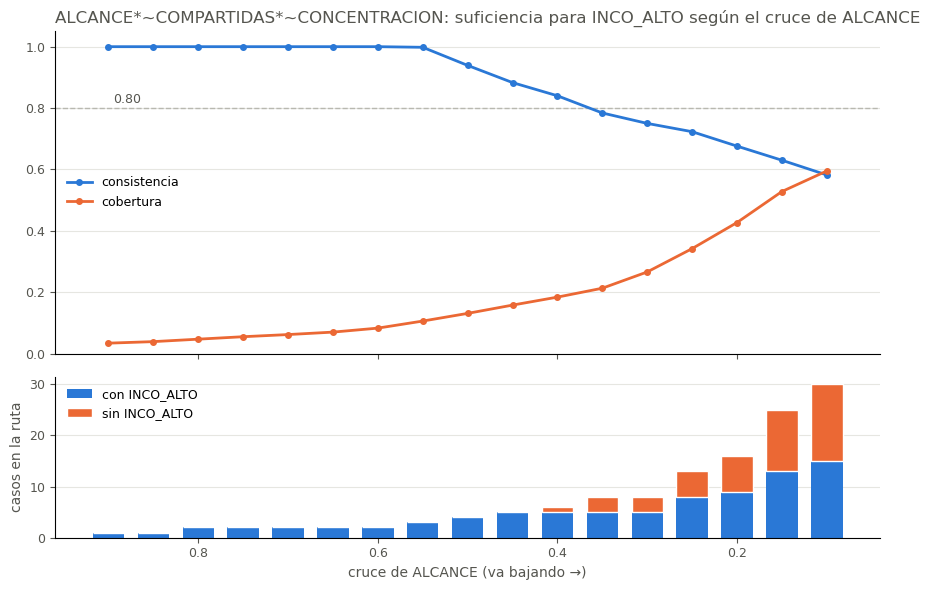

In [16]:
fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})

arriba.axhline(0.80, color=GRIS, linestyle="--", linewidth=1)
arriba.plot(ruta_df["cruce_ALCANCE"], ruta_df["consistencia"], color=AZUL, linewidth=2, marker="o", markersize=4,
            label="consistencia")
arriba.plot(ruta_df["cruce_ALCANCE"], ruta_df["cobertura"], color=NARANJA, linewidth=2, marker="o", markersize=4,
            label="cobertura")
arriba.text(0.895, 0.815, "0.80", color=TEXTO, fontsize=9)
arriba.set_ylim(0, 1.05)
arriba.legend(frameon=False, fontsize=9, loc="center left")
arriba.set_title(f"{RUTA}: suficiencia para INCO_ALTO según el cruce de ALCANCE", color=TEXTO, fontsize=12, loc="left")

con = ruta_df["con_INCO_ALTO"].str.count(",") + (ruta_df["con_INCO_ALTO"] != "")
sin = ruta_df["sin_INCO_ALTO"].str.count(",") + (ruta_df["sin_INCO_ALTO"] != "")
abajo.bar(ruta_df["cruce_ALCANCE"], con, width=0.035, color=AZUL, label="con INCO_ALTO")
abajo.bar(ruta_df["cruce_ALCANCE"], sin, width=0.035, bottom=con, color=NARANJA, edgecolor="white", linewidth=1,
          label="sin INCO_ALTO")
abajo.set_ylabel("casos en la ruta", color=TEXTO)
abajo.set_xlabel("cruce de ALCANCE (va bajando →)", color=TEXTO)
abajo.legend(frameon=False, fontsize=9, loc="upper left")

for eje in (arriba, abajo):
    eje.spines[["top", "right"]].set_visible(False)
    eje.tick_params(colors=TEXTO, labelsize=9)
    eje.grid(axis="y", color="#e6e6e1", linewidth=0.8)
    eje.set_axisbelow(True)
abajo.invert_xaxis()  # ejes compartidos: invertir una sola vez

fig.tight_layout()
plt.show()

### ¿Cómo leer el gráfico?

La línea azul muestra la consistencia de la ruta y la naranja su cobertura. A medida que baja el cruce de `ALCANCE`, la ruta incluye más casos: la cobertura sube, pero la consistencia baja porque empiezan a ingresar GORE–año sin INCO alto (barras naranjas). La consistencia cruza el umbral de 0.80 entre los cruces de 0.40 y 0.35. Las barras no muestran a Tumbes 2024, cuya membresía en `INCO_ALTO` es exactamente 0.5.

Este es el **intercambio entre consistencia y cobertura** típico de QCA: una definición más exigente de alto alcance produce una relación más consistente, pero que vale para menos gobiernos regionales.

## Guardar los resultados del barrido

Guardaremos `barrido_qca_resultados.csv`, con una fila por combinación de cruces y frecuencia mínima, la solución encontrada, sus parámetros y los casos que la sostienen.

In [17]:
barrido_qca.to_csv("barrido_qca_resultados.csv", index=False)
print("Archivo creado: barrido_qca_resultados.csv | filas:", len(barrido_qca))

# Descarga del archivo cuando el notebook se ejecuta en Google Colab
try:
    from google.colab import files
    files.download("barrido_qca_resultados.csv")
except ImportError:
    print("Fuera de Colab: el archivo quedó guardado en la carpeta del notebook.")

Archivo creado: barrido_qca_resultados.csv | filas: 19683
Fuera de Colab: el archivo quedó guardado en la carpeta del notebook.


## Síntesis de los hallazgos

1. **Con la calibración principal aparece una solución para `INCO_ALTO`** (consistencia 0.842, cobertura 0.269), algo que no ocurría en `Tesis_QCA_v2`. Sin embargo, sus tres rutas descansan en uno o dos GORE–año cada una y se contradicen entre sí, por lo que no constituyen un patrón general.
2. **El barrido muestra que la aparición de soluciones depende sobre todo del umbral de `ALCANCE`.** Con frecuencia mínima de 3 casos, un cruce de 0.50 en `ALCANCE` produce una solución en el 88 % de las combinaciones de las demás condiciones.
3. **La ruta que más se repite es `ALCANCE*~COMPARTIDAS*~CONCENTRACION`**: gobiernos regionales que contratan con muchas empresas, exclusivas del GORE y con montos dispersos. Es suficiente para `INCO_ALTO` cuando el alto alcance se define a partir de unas 57 empresas contratistas en el año.
4. **La ruta se sostiene en un grupo reducido de casos**: Áncash 2021, Áncash 2022, Junín 2024 y Lima 2024 (y Loreto 2024 según el cruce). Su cobertura no supera 0.20 mientras la consistencia se mantiene por encima de 0.80.

Como el barrido es exploratorio, estos resultados deben presentarse como un **mapa de sensibilidad**: la ruta no aparece por una calibración elegida a medida, sino que se mantiene en un rango amplio de umbrales de las demás condiciones, aunque solo en el extremo alto de `ALCANCE` y para pocos gobiernos regionales. El siguiente paso sería examinar estos casos con conocimiento cualitativo: qué tienen en común Áncash, Junín y Lima en su forma de contratar obras.